# Análise dos preços dos combustíveis em 2025

## 1. Coleta dos dados

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração dos gráficos
sns.set_theme(style="whitegrid")

print("Bibliotecas importadas com sucesso!")


Bibliotecas importadas com sucesso!


In [3]:

# Leitura das bases de dados
arquivo_1 = "../dados/brutos/combustiveis_1_semestre_2025.csv"
arquivo_2 = "../dados/brutos/combustiveis_2_semestre_2025.csv"

dados_1 = pd.read_csv(
    arquivo_1,
    sep=";",
    encoding="utf-8-sig",
    dtype=str
)

dados_2 = pd.read_csv(
    arquivo_2,
    sep=";",
    encoding="utf-8-sig",
    dtype=str
)

# União dos dois semestres
dados = pd.concat(
    [dados_1, dados_2],
    ignore_index=True
)

print("Total de registros:", len(dados))
print(dados.head())


Total de registros: 813731
  Regiao - Sigla Estado - Sigla Municipio  \
0             NE             CE    SOBRAL   
1             NE             CE    SOBRAL   
2             NE             CE    SOBRAL   
3             NE             CE    SOBRAL   
4             NE             CE    SOBRAL   

                                             Revenda      CNPJ da Revenda  \
0  ECONOGÁS DO BRASIL DIST. DERIV. DE PET. BIOC. ...   08.775.979/0002-62   
1  ECONOGÁS DO BRASIL DIST. DERIV. DE PET. BIOC. ...   08.775.979/0002-62   
2  ECONOGÁS DO BRASIL DIST. DERIV. DE PET. BIOC. ...   08.775.979/0002-62   
3  ECONOGÁS DO BRASIL DIST. DERIV. DE PET. BIOC. ...   08.775.979/0002-62   
4                           V.C.EMPREENDIMENTOS LTDA   03.551.935/0002-35   

                            Nome da Rua Numero Rua  Complemento  \
0     RUA TABELIÃO IDELFONSO CAVALCANTI        455          NaN   
1     RUA TABELIÃO IDELFONSO CAVALCANTI        455          NaN   
2     RUA TABELIÃO IDELFONSO CAVALCANT

In [4]:

# Criando uma cópia da base original
dados_originais = dados.copy()

print("Base original preservada!")
print("Quantidade de registros:", len(dados_originais))


Base original preservada!
Quantidade de registros: 813731


## 2. Limpeza e preparação dos dados

In [5]:

# Criando uma cópia para tratamento
dados_limpos = dados.copy()

# Identificando as colunas de texto
colunas_texto = dados_limpos.select_dtypes(
    include=["object", "str"]
).columns

# Removendo espaços extras
for coluna in colunas_texto:
    dados_limpos[coluna] = dados_limpos[coluna].str.strip()

# Padronizando os nomes dos produtos
dados_limpos["Produto"] = (
    dados_limpos["Produto"].str.upper()
)

# Exibindo a quantidade de registros por produto
print(dados_limpos["Produto"].value_counts())


Produto
GASOLINA              212423
ETANOL                177753
GASOLINA ADITIVADA    165691
DIESEL S10            144541
DIESEL                 85969
GNV                    18240
Name: count, dtype: int64


In [6]:

# Convertendo os preços para formato numérico
dados_limpos["Valor de Venda"] = pd.to_numeric(
    dados_limpos["Valor de Venda"]
    .str.replace(",", ".", regex=False),
    errors="coerce"
)

# Convertendo as datas
dados_limpos["Data da Coleta"] = pd.to_datetime(
    dados_limpos["Data da Coleta"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Conferindo os resultados
print(dados_limpos[
    ["Produto", "Valor de Venda", "Data da Coleta"]
].head())

print("\nTipos de dados:")
print(dados_limpos[
    ["Valor de Venda", "Data da Coleta"]
].dtypes)


              Produto  Valor de Venda Data da Coleta
0            GASOLINA            6.29     2025-01-01
1  GASOLINA ADITIVADA            6.49     2025-01-01
2          DIESEL S10            6.19     2025-01-01
3              ETANOL            5.19     2025-01-01
4            GASOLINA            6.53     2025-01-01

Tipos de dados:
Valor de Venda           float64
Data da Coleta    datetime64[us]
dtype: object


In [23]:

# Selecionando os combustíveis da pesquisa
combustiveis = ["GASOLINA", "ETANOL"]

dados_limpos = dados_limpos[
    dados_limpos["Produto"].isin(combustiveis)
].copy()

# Verificando os produtos selecionados
print(dados_limpos["Produto"].value_counts())

print("\nTotal de registros selecionados:")
print(len(dados_limpos))


Produto
GASOLINA    212423
ETANOL      177753
Name: count, dtype: int64

Total de registros selecionados:
390176


In [24]:

# Colunas essenciais para a análise
colunas_essenciais = [
    "Regiao - Sigla",
    "Estado - Sigla",
    "Municipio",
    "Produto",
    "Data da Coleta",
    "Valor de Venda"
]

# Verificando valores ausentes
print("Valores ausentes:")
print(dados_limpos[colunas_essenciais].isnull().sum())

# Verificando duplicidades exatas
print("\nRegistros duplicados:")
print(dados_limpos.duplicated().sum())


Valores ausentes:
Regiao - Sigla    0
Estado - Sigla    0
Municipio         0
Produto           0
Data da Coleta    0
Valor de Venda    0
dtype: int64

Registros duplicados:
0


In [25]:

# Verificando preços iguais ou inferiores a zero
precos_invalidos = (
    dados_limpos["Valor de Venda"].isna()
    | (dados_limpos["Valor de Venda"] <= 0)
)

print("Preços inválidos:", precos_invalidos.sum())


Preços inválidos: 0


In [26]:

# Quantidade antes do tratamento final
total_antes = len(dados_limpos)

# Removendo registros com informações essenciais ausentes
dados_limpos = dados_limpos.dropna(
    subset=colunas_essenciais
)

# Removendo preços inválidos
dados_limpos = dados_limpos[
    dados_limpos["Valor de Venda"] > 0
]

# Removendo duplicidades exatas
dados_limpos = dados_limpos.drop_duplicates()

# Mantendo somente registros de 2025
dados_limpos = dados_limpos[
    dados_limpos["Data da Coleta"].dt.year == 2025
].copy()

# Criando coluna de identificação do semestre
dados_limpos["Semestre"] = np.where(
    dados_limpos["Data da Coleta"].dt.month <= 6,
    "1º Semestre",
    "2º Semestre"
)

# Resultado do tratamento
print("Registros antes:", total_antes)
print("Registros depois:", len(dados_limpos))
print("Registros removidos:", total_antes - len(dados_limpos))

print("\nDistribuição por combustível:")
print(dados_limpos["Produto"].value_counts())

print("\nDistribuição por semestre:")
print(dados_limpos["Semestre"].value_counts())


Registros antes: 390176
Registros depois: 390176
Registros removidos: 0

Distribuição por combustível:
Produto
GASOLINA    212423
ETANOL      177753
Name: count, dtype: int64

Distribuição por semestre:
Semestre
1º Semestre    203416
2º Semestre    186760
Name: count, dtype: int64


In [27]:

# Resumo da base tratada
print("DIMENSÕES DA BASE:")
print(dados_limpos.shape)

print("\nPERÍODO DOS DADOS:")
print(dados_limpos["Data da Coleta"].min())
print(dados_limpos["Data da Coleta"].max())

print("\nREGIÕES:")
print(sorted(dados_limpos["Regiao - Sigla"].unique()))

print("\nESTADOS:")
print(dados_limpos["Estado - Sigla"].nunique())

print("\nVALORES AUSENTES:")
print(dados_limpos[colunas_essenciais].isnull().sum())

print("\nDUPLICIDADES:")
print(dados_limpos.duplicated().sum())


DIMENSÕES DA BASE:
(390176, 17)

PERÍODO DOS DADOS:
2025-01-01 00:00:00
2025-12-31 00:00:00

REGIÕES:
['CO', 'N', 'NE', 'S', 'SE']

ESTADOS:
27

VALORES AUSENTES:
Regiao - Sigla    0
Estado - Sigla    0
Municipio         0
Produto           0
Data da Coleta    0
Valor de Venda    0
dtype: int64

DUPLICIDADES:
0


In [28]:

# Salvando a base tratada
dados_limpos.to_csv(
    "../dados/tratados/combustiveis_2025_tratados.csv",
    sep=";",
    decimal=",",
    index=False,
    encoding="utf-8-sig"
)

print("Base tratada salva com sucesso!")


Base tratada salva com sucesso!


## 3. Análise exploratória e estatística
### Estatística descritiva dos combustíveis.

In [29]:

# Estatística descritiva dos combustíveis

estatisticas = dados_limpos.groupby("Produto")["Valor de Venda"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

# Renomeando as colunas
estatisticas.columns = [
    "Quantidade",
    "Média",
    "Mediana",
    "Desvio Padrão",
    "Mínimo",
    "Máximo"
]

print(estatisticas.round(2))


          Quantidade  Média  Mediana  Desvio Padrão  Mínimo  Máximo
Produto                                                            
ETANOL        177753   4.46     4.39           0.46    3.09    7.44
GASOLINA      212423   6.25     6.19           0.41    4.99    9.29


In [30]:

# Média dos preços por combustível e semestre

media_semestres = dados_limpos.groupby(
    ["Produto", "Semestre"]
)["Valor de Venda"].mean().unstack()

print(media_semestres.round(2))


Semestre  1º Semestre  2º Semestre
Produto                           
ETANOL           4.48         4.44
GASOLINA         6.29         6.20


In [31]:

# Calculando a variação percentual entre os semestres

variacao = (
    (media_semestres["2º Semestre"] -
     media_semestres["1º Semestre"])
    / media_semestres["1º Semestre"]
) * 100

print("Variação percentual dos preços:")
print(variacao.round(2))


Variação percentual dos preços:
Produto
ETANOL     -0.94
GASOLINA   -1.41
dtype: float64


In [32]:

# Criando uma coluna com o mês da coleta
dados_limpos["Mes"] = (
    dados_limpos["Data da Coleta"].dt.to_period("M")
)

# Calculando a média mensal por combustível
media_mensal = dados_limpos.groupby(
    ["Mes", "Produto"]
)["Valor de Venda"].mean().unstack()

print(media_mensal.round(2))


Produto  ETANOL  GASOLINA
Mes                      
2025-01    4.37      6.18
2025-02    4.55      6.37
2025-03    4.54      6.35
2025-04    4.51      6.32
2025-05    4.48      6.28
2025-06    4.42      6.23
2025-07    4.38      6.21
2025-08    4.37      6.18
2025-09    4.42      6.19
2025-10    4.45      6.22
2025-11    4.44      6.19
2025-12    4.53      6.20


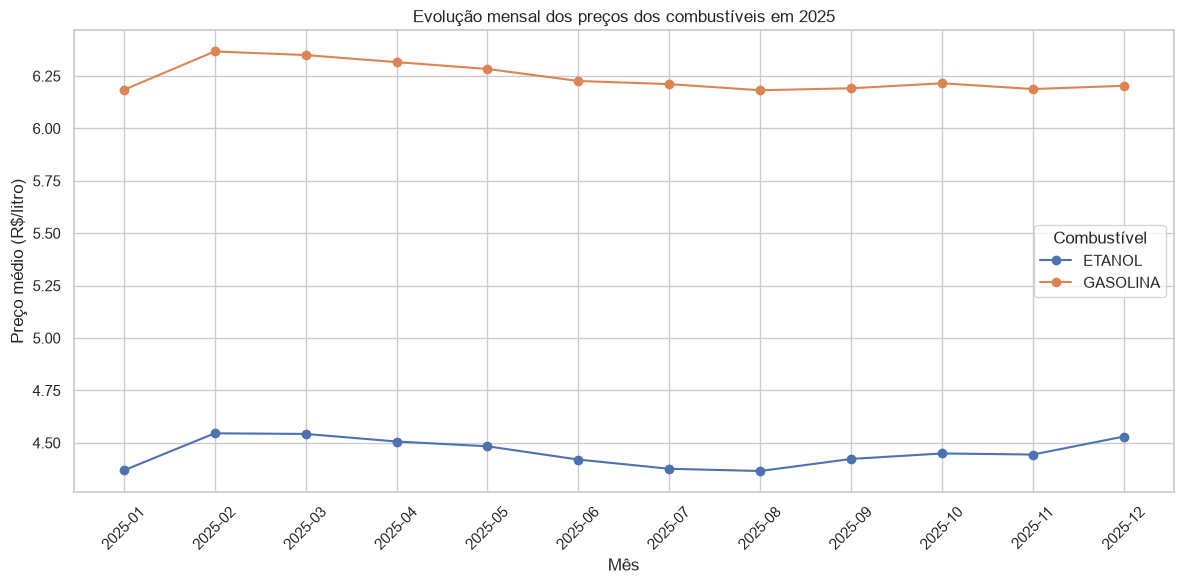

In [33]:

# Gráfico de evolução mensal dos preços

plt.figure(figsize=(12, 6))

for combustivel in media_mensal.columns:
    plt.plot(
        media_mensal.index.astype(str),
        media_mensal[combustivel],
        marker="o",
        label=combustivel
    )

plt.title("Evolução mensal dos preços dos combustíveis em 2025")
plt.xlabel("Mês")
plt.ylabel("Preço médio (R$/litro)")
plt.xticks(rotation=45)
plt.legend(title="Combustível")
plt.grid(True)
plt.tight_layout()

plt.show()


In [34]:

# Média dos preços por estado e combustível

media_estados = dados_limpos.groupby(
    ["Estado - Sigla", "Produto"]
)["Valor de Venda"].mean().unstack()

print(media_estados.round(2))


Produto         ETANOL  GASOLINA
Estado - Sigla                  
AC                5.45      7.67
AL                4.97      6.33
AM                5.43      7.23
AP                5.43      6.04
BA                4.79      6.39
CE                5.12      6.37
DF                4.64      6.44
ES                4.53      6.26
GO                4.45      6.29
MA                4.94      6.13
MG                4.33      6.13
MS                4.08      6.21
MT                4.16      6.26
PA                4.84      6.40
PB                4.49      6.06
PE                4.77      6.33
PI                4.63      5.93
PR                4.46      6.43
RJ                4.61      6.15
RN                5.00      6.33
RO                5.21      6.91
RR                5.16      6.95
RS                4.87      6.22
SC                4.74      6.39
SE                4.85      6.55
SP                4.10      6.09
TO                4.77      6.53


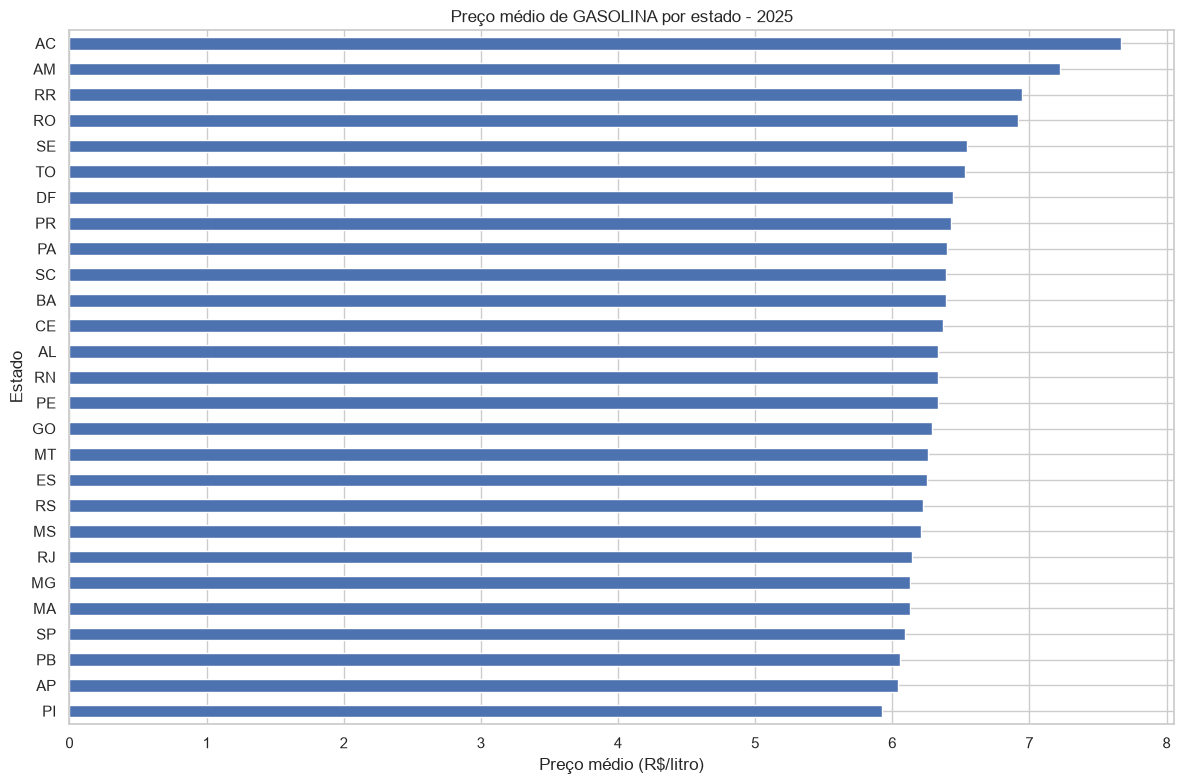

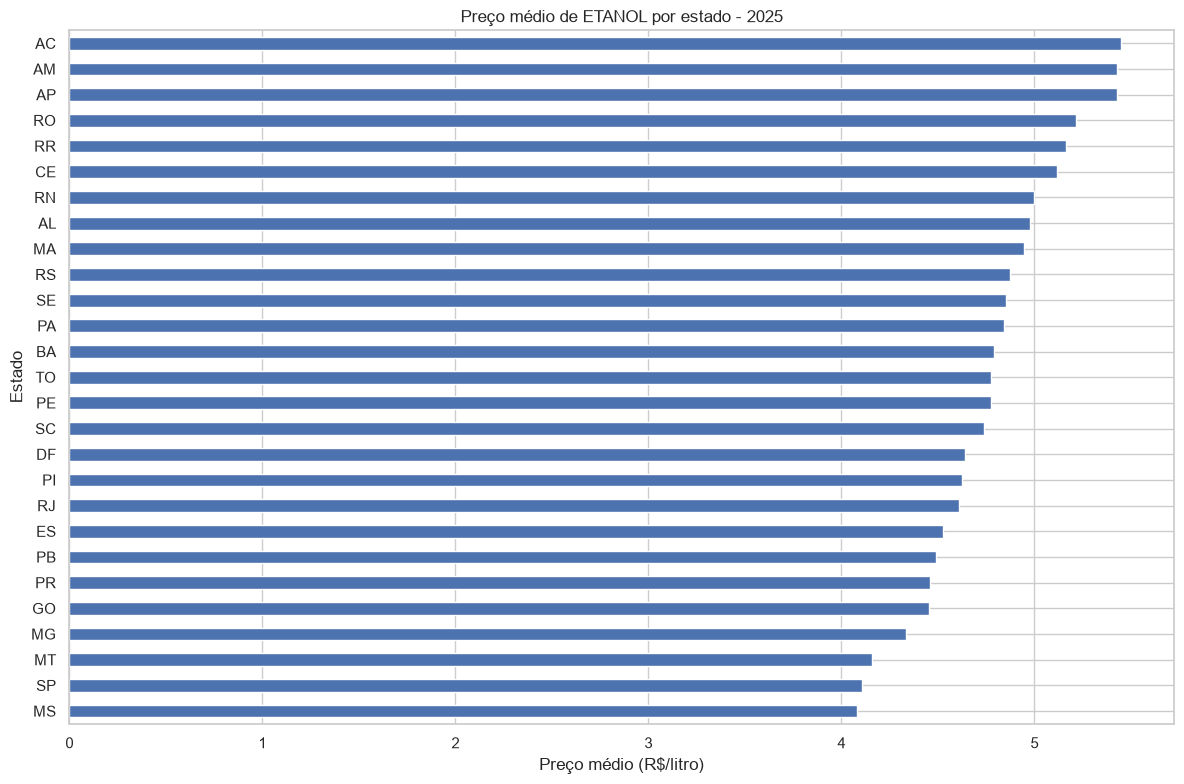

In [36]:

# Gráfico de preços médios por estado

for combustivel in ["GASOLINA", "ETANOL"]:

    ranking = media_estados[combustivel].sort_values()

    plt.figure(figsize=(12, 8))

    ranking.plot(kind="barh")

    plt.title(f"Preço médio de {combustivel} por estado - 2025")
    plt.xlabel("Preço médio (R$/litro)")
    plt.ylabel("Estado")

    plt.tight_layout()
    plt.show()


## 4- Análise comparativa por estado

In [38]:

# Média anual por estado e combustível

media_estados = dados_limpos.groupby(
    ["Estado - Sigla", "Produto"]
)["Valor de Venda"].mean().unstack()

# Ranking da gasolina
gasolina_ranking = media_estados["GASOLINA"].sort_values(
    ascending=False
)

# Ranking do etanol
etanol_ranking = media_estados["ETANOL"].sort_values(
    ascending=False
)

print("GASOLINA - 5 estados mais caros:")
print(gasolina_ranking.head(5).round(2))

print("\nGASOLINA - 5 estados mais baratos:")
print(gasolina_ranking.tail(5).sort_values().round(2))

print("\nETANOL - 5 estados mais caros:")
print(etanol_ranking.head(5).round(2))

print("\nETANOL - 5 estados mais baratos:")
print(etanol_ranking.tail(5).sort_values().round(2))


GASOLINA - 5 estados mais caros:
Estado - Sigla
AC    7.67
AM    7.23
RR    6.95
RO    6.91
SE    6.55
Name: GASOLINA, dtype: float64

GASOLINA - 5 estados mais baratos:
Estado - Sigla
PI    5.93
AP    6.04
PB    6.06
SP    6.09
MA    6.13
Name: GASOLINA, dtype: float64

ETANOL - 5 estados mais caros:
Estado - Sigla
AC    5.45
AM    5.43
AP    5.43
RO    5.21
RR    5.16
Name: ETANOL, dtype: float64

ETANOL - 5 estados mais baratos:
Estado - Sigla
MS    4.08
SP    4.10
MT    4.16
MG    4.33
GO    4.45
Name: ETANOL, dtype: float64


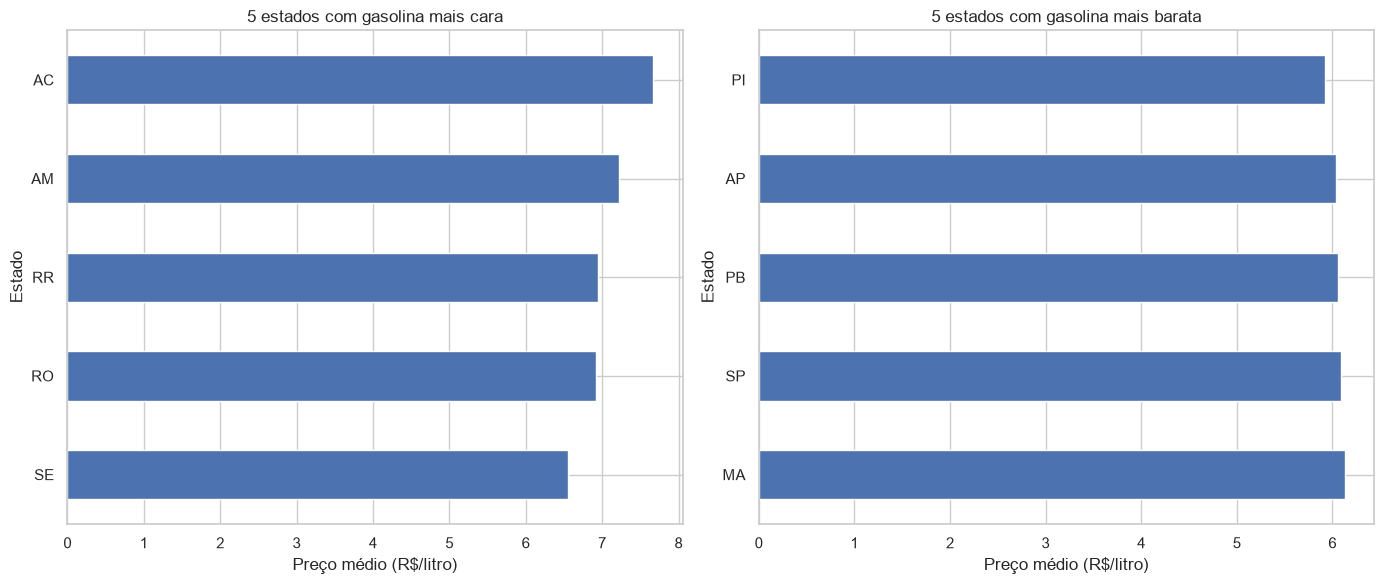

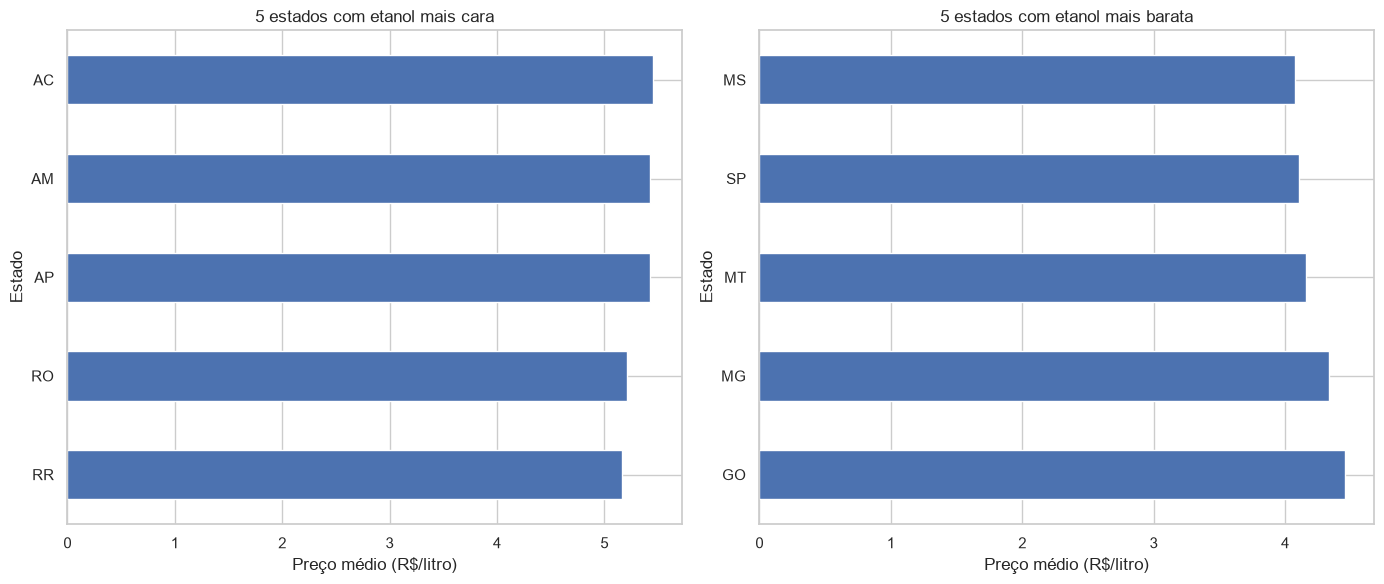

In [39]:

# Gráficos dos cinco estados mais caros e mais baratos

for combustivel in ["GASOLINA", "ETANOL"]:

    ranking = media_estados[combustivel]

    mais_caros = ranking.nlargest(5).sort_values()
    mais_baratos = ranking.nsmallest(5).sort_values(ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    mais_caros.plot(
        kind="barh",
        ax=axes[0],
        title=f"5 estados com {combustivel.lower()} mais cara"
    )

    mais_baratos.plot(
        kind="barh",
        ax=axes[1],
        title=f"5 estados com {combustivel.lower()} mais barata"
    )

    axes[0].set_xlabel("Preço médio (R$/litro)")
    axes[1].set_xlabel("Preço médio (R$/litro)")

    axes[0].set_ylabel("Estado")
    axes[1].set_ylabel("Estado")

    plt.tight_layout()
    plt.show()


### Estados que mais aumentaram e diminuíram os preços

In [40]:

# Média por estado, combustível e semestre

medias_uf_semestre = dados_limpos.groupby(
    ["Estado - Sigla", "Produto", "Semestre"]
)["Valor de Venda"].mean().unstack()

# Calculando a variação percentual por estado e combustível

variacao_estados = (
    (medias_uf_semestre["2º Semestre"] -
     medias_uf_semestre["1º Semestre"])
    / medias_uf_semestre["1º Semestre"]
) * 100

print("Variação percentual por estado:")
print(variacao_estados.round(2))


Variação percentual por estado:
Estado - Sigla  Produto 
AC              ETANOL     -0.72
                GASOLINA   -1.75
AL              ETANOL      0.94
                GASOLINA   -2.26
AM              ETANOL      1.89
                GASOLINA   -2.06
AP              ETANOL      0.68
                GASOLINA   -0.02
BA              ETANOL     -1.75
                GASOLINA   -2.25
CE              ETANOL     -2.67
                GASOLINA   -2.30
DF              ETANOL     -0.88
                GASOLINA   -1.75
ES              ETANOL     -1.45
                GASOLINA   -1.70
GO              ETANOL      1.42
                GASOLINA   -0.14
MA              ETANOL     -1.27
                GASOLINA   -3.20
MG              ETANOL     -0.51
                GASOLINA   -1.66
MS              ETANOL     -4.19
                GASOLINA   -2.41
MT              ETANOL      3.58
                GASOLINA    0.64
PA              ETANOL     -1.46
                GASOLINA   -1.58
PB              ETA

In [42]:
medias_uf_semestre = dados_limpos.groupby(
    ["Estado - Sigla", "Produto", "Semestre"]
)["Valor de Venda"].mean().unstack()

variacao_estados = (
    (medias_uf_semestre["2º Semestre"] -
     medias_uf_semestre["1º Semestre"])
    / medias_uf_semestre["1º Semestre"]
) * 100

# Organiza os dados com os combustíveis nas colunas
variacao_estados = variacao_estados.unstack(level="Produto")

print(variacao_estados.head())

Produto           ETANOL  GASOLINA
Estado - Sigla                    
AC             -0.722430 -1.746005
AL              0.944469 -2.264548
AM              1.886952 -2.062786
AP              0.682717 -0.020392
BA             -1.752875 -2.249616


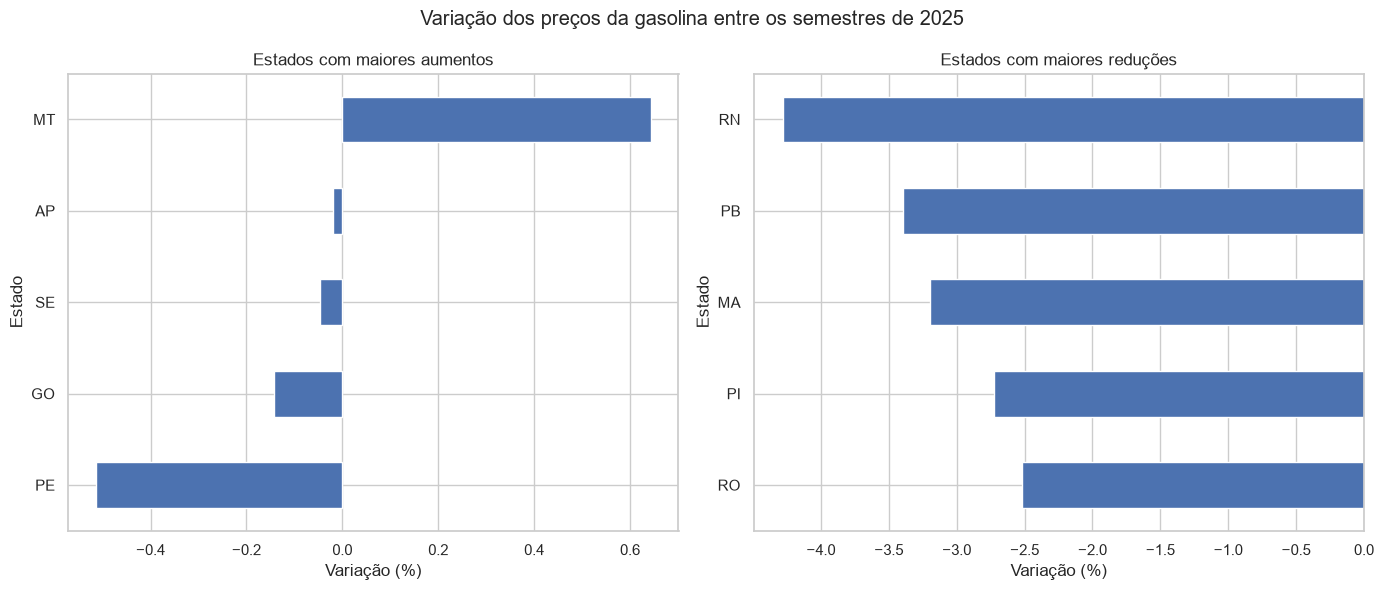

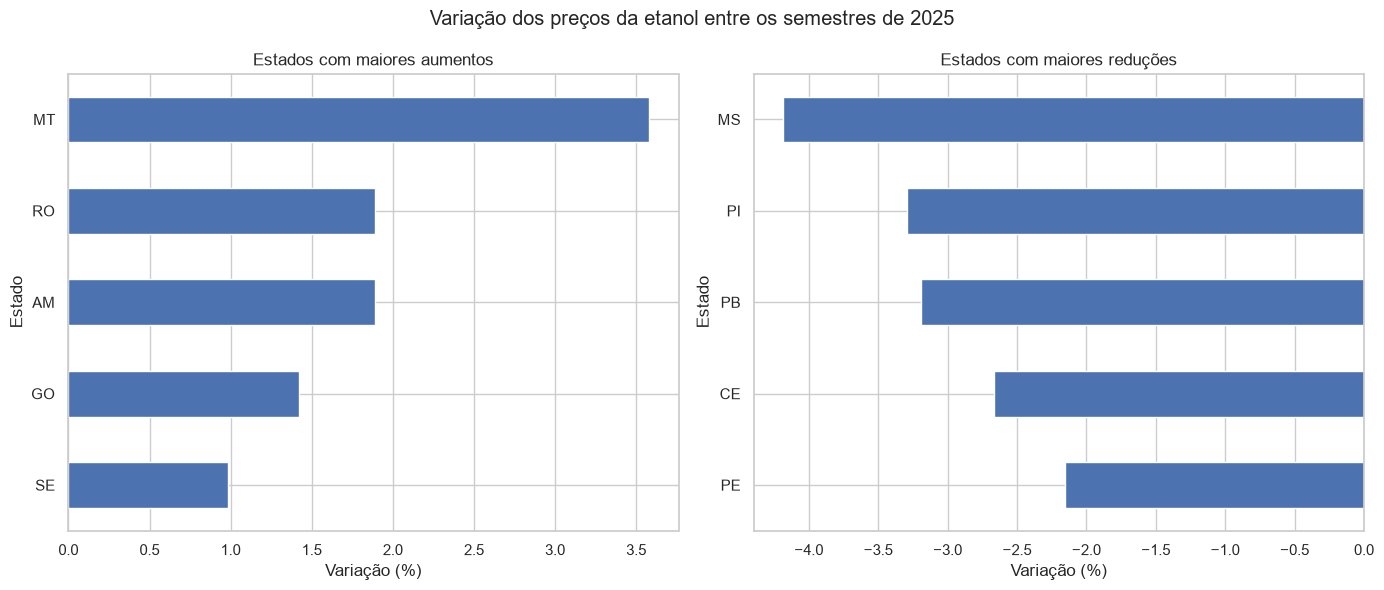

In [43]:
for combustivel in ["GASOLINA", "ETANOL"]:

    variacoes = variacao_estados[combustivel].dropna()

    maiores_altas = variacoes.nlargest(5).sort_values()
    maiores_quedas = variacoes.nsmallest(5).sort_values(ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    maiores_altas.plot(
        kind="barh",
        ax=axes[0],
        title="Estados com maiores aumentos"
    )

    maiores_quedas.plot(
        kind="barh",
        ax=axes[1],
        title="Estados com maiores reduções"
    )

    axes[0].set_xlabel("Variação (%)")
    axes[1].set_xlabel("Variação (%)")

    axes[0].set_ylabel("Estado")
    axes[1].set_ylabel("Estado")

    fig.suptitle(
        f"Variação dos preços da {combustivel.lower()} entre os semestres de 2025"
    )

    plt.tight_layout()
    plt.show()